In [1]:
!pip -q install datasets huggingface_hub scipy pandas numpy matplotlib seaborn

In [2]:
import re
import math
import random
import numpy as np
import pandas as pd

from collections import Counter, defaultdict

from datasets import load_dataset

from scipy.sparse import csr_matrix, hstack
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

In [4]:
# ============================================================
# CELL 3 — DEFINE THE 23 INDICCORPV2 LANGUAGES
# ============================================================

languages = {
    "asm_Beng": "Assamese",
    "ben_Beng": "Bengali",
    "brx_Deva": "Bodo",
    "doi_Deva": "Dogri",
    "gom_Deva": "Konkani",
    "guj_Gujr": "Gujarati",
    "hin_Deva": "Hindi",
    "kan_Knda": "Kannada",
    "kas_Arab": "Kashmiri",
    "mai_Deva": "Maithili",
    "mal_Mlym": "Malayalam",
    "mar_Deva": "Marathi",
    "mni_Mtei": "Manipuri",
    "npi_Deva": "Nepali",
    "ory_Orya": "Odia",
    "pan_Guru": "Punjabi",
    "san_Deva": "Sanskrit",
    "snd_Deva": "Sindhi",
    "tam_Taml": "Tamil",
    "tel_Telu": "Telugu",
    "urd_Arab": "Urdu",
    "khasi": "Khasi",
    "santhali": "Santali"
}

print("Number of languages:", len(languages))

for code, name in languages.items():
    print(f"{code:12s} -> {name}")

Number of languages: 23
asm_Beng     -> Assamese
ben_Beng     -> Bengali
brx_Deva     -> Bodo
doi_Deva     -> Dogri
gom_Deva     -> Konkani
guj_Gujr     -> Gujarati
hin_Deva     -> Hindi
kan_Knda     -> Kannada
kas_Arab     -> Kashmiri
mai_Deva     -> Maithili
mal_Mlym     -> Malayalam
mar_Deva     -> Marathi
mni_Mtei     -> Manipuri
npi_Deva     -> Nepali
ory_Orya     -> Odia
pan_Guru     -> Punjabi
san_Deva     -> Sanskrit
snd_Deva     -> Sindhi
tam_Taml     -> Tamil
tel_Telu     -> Telugu
urd_Arab     -> Urdu
khasi        -> Khasi
santhali     -> Santali


In [5]:
# CELL 4 — DATASET SIZE

SAMPLES_PER_LANGUAGE = 1500

NUM_LANGUAGES = len(languages)

TOTAL_SAMPLES = (
    SAMPLES_PER_LANGUAGE * NUM_LANGUAGES
)

print("Samples per language :", SAMPLES_PER_LANGUAGE)
print("Number of languages  :", NUM_LANGUAGES)
print("Expected total       :", TOTAL_SAMPLES)

Samples per language : 1500
Number of languages  : 23
Expected total       : 34500


In [6]:
# TEST INDICCORPV2 STREAMING

print("Testing IndicCorpV2 streaming with Hindi...")

test_dataset = load_dataset(
    "ai4bharat/IndicCorpV2",
    "indiccorp_v2",
    split="hin_Deva",
    streaming=True
)

print("Dataset loaded successfully!")
print("Dataset type:", type(test_dataset))

print("\nFirst record:\n")

first_record = next(iter(test_dataset))

print(first_record["text"][:1000])

print("\nStreaming test completed successfully.")

Testing IndicCorpV2 streaming with Hindi...


README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

Dataset loaded successfully!
Dataset type: <class 'datasets.iterable_dataset.IterableDataset'>

First record:

लोगों को बिलों संबंधी सुविधा देना ही उनका काम

Streaming test completed successfully.


In [7]:
#SENTENCE TOKENIZATION

def split_into_sentences(text):

    if not isinstance(text, str):
        return []

    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # Split at:
    # .  !  ?  ।  ॥
    sentences = re.split(
        r'(?<=[.!?।॥])\s+',
        text
    )

    cleaned_sentences = []

    for sentence in sentences:

        sentence = sentence.strip()

        # Remove very short fragments
        if len(sentence) < 10:
            continue

        # Require at least 3 tokens
        if len(sentence.split()) < 3:
            continue

        cleaned_sentences.append(sentence)

    return cleaned_sentences


# Test tokenizer
sample_text = """
भारत एक विविधताओं से भरा हुआ देश है।
यहाँ अनेक भाषाएँ बोली जाती हैं।
भारत की संस्कृति बहुत समृद्ध है।
"""

print(split_into_sentences(sample_text))

['भारत एक विविधताओं से भरा हुआ देश है।', 'यहाँ अनेक भाषाएँ बोली जाती हैं।', 'भारत की संस्कृति बहुत समृद्ध है।']


In [8]:
# ============================================================
# CELL 7 — COLLECT 1500 SENTENCES PER LANGUAGE
# ============================================================

all_texts = []
all_labels = []

failed_languages = []

for lang_code, lang_name in languages.items():

    print("\n" + "=" * 70)
    print(f"Language : {lang_name}")
    print(f"Split    : {lang_code}")
    print("=" * 70)

    sentences = []

    try:

        # Stream only this language split
        dataset = load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            split=lang_code,
            streaming=True
        )

        # Read records until 1500 sentences
        for record in dataset:

            text = record["text"]

            sentence_list = split_into_sentences(
                text
            )

            for sentence in sentence_list:

                sentences.append(
                    sentence
                )

                if (
                    len(sentences)
                    >= SAMPLES_PER_LANGUAGE
                ):
                    break

            if (
                len(sentences)
                >= SAMPLES_PER_LANGUAGE
            ):
                break


        # Keep exactly 1500
        sentences = sentences[
            :SAMPLES_PER_LANGUAGE
        ]


        print(
            f"Collected "
            f"{len(sentences)} / "
            f"{SAMPLES_PER_LANGUAGE}"
        )


        # Check whether enough samples were found

        if (
            len(sentences)
            < SAMPLES_PER_LANGUAGE
        ):

            failed_languages.append(
                (
                    lang_code,
                    lang_name,
                    len(sentences)
                )
            )


        # Store texts and labels

        all_texts.extend(
            sentences
        )

        all_labels.extend(
            [lang_code] *
            len(sentences)
        )


    except Exception as e:

        print(
            f"ERROR for {lang_code}: {e}"
        )

        failed_languages.append(
            (
                lang_code,
                lang_name,
                str(e)
            )
        )


# ============================================================
# CREATE DATAFRAME
# ============================================================

df = pd.DataFrame({
    "text": all_texts,
    "label": all_labels
})


# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 70)
print("DATA COLLECTION COMPLETED")
print("=" * 70)

print(
    "Total samples collected:",
    len(df)
)

print(
    "Languages collected:",
    df["label"].nunique()
)

print("\nSamples per language:")

print(
    df["label"]
    .value_counts()
    .sort_index()
)


# ============================================================
# CHECK FOR FAILURES
# ============================================================

if failed_languages:

    print(
        "\nWARNING — SOME LANGUAGES "
        "DID NOT REACH 1500:"
    )

    for item in failed_languages:
        print(item)

else:

    print(
        "\nSUCCESS: "
        "All 23 languages have 1500 samples."
    )


Language : Assamese
Split    : asm_Beng
Collected 1500 / 1500

Language : Bengali
Split    : ben_Beng
Collected 1500 / 1500

Language : Bodo
Split    : brx_Deva
Collected 1500 / 1500

Language : Dogri
Split    : doi_Deva
Collected 1500 / 1500

Language : Konkani
Split    : gom_Deva
Collected 1500 / 1500

Language : Gujarati
Split    : guj_Gujr
Collected 1500 / 1500

Language : Hindi
Split    : hin_Deva
Collected 1500 / 1500

Language : Kannada
Split    : kan_Knda
Collected 1500 / 1500

Language : Kashmiri
Split    : kas_Arab
Collected 1500 / 1500

Language : Maithili
Split    : mai_Deva
Collected 1500 / 1500

Language : Malayalam
Split    : mal_Mlym
Collected 1500 / 1500

Language : Marathi
Split    : mar_Deva
Collected 1500 / 1500

Language : Manipuri
Split    : mni_Mtei
Collected 1500 / 1500

Language : Nepali
Split    : npi_Deva
Collected 1500 / 1500

Language : Odia
Split    : ory_Orya
Collected 1500 / 1500

Language : Punjabi
Split    : pan_Guru
Collected 1500 / 1500

Language : 

In [9]:
# ============================================================
# CELL 8 — VERIFY CLASS BALANCE
# ============================================================

counts = df["label"].value_counts().sort_index()

print(counts)

print("\nMinimum samples in a class:", counts.min())
print("Maximum samples in a class:", counts.max())

if (
    len(df) == 34500
    and counts.min() == 1500
    and counts.max() == 1500
):
    print("\n✓ DATASET IS PERFECTLY BALANCED")
else:
    print("\n✗ DATASET SIZE/BALANCE NEEDS CHECKING")

label
asm_Beng    1500
ben_Beng    1500
brx_Deva    1500
doi_Deva    1500
gom_Deva    1500
guj_Gujr    1500
hin_Deva    1500
kan_Knda    1500
kas_Arab    1500
khasi       1500
mai_Deva    1500
mal_Mlym    1500
mar_Deva    1500
mni_Mtei    1500
npi_Deva    1500
ory_Orya    1500
pan_Guru    1500
san_Deva    1500
santhali    1500
snd_Deva    1500
tam_Taml    1500
tel_Telu    1500
urd_Arab    1500
Name: count, dtype: int64

Minimum samples in a class: 1500
Maximum samples in a class: 1500

✓ DATASET IS PERFECTLY BALANCED


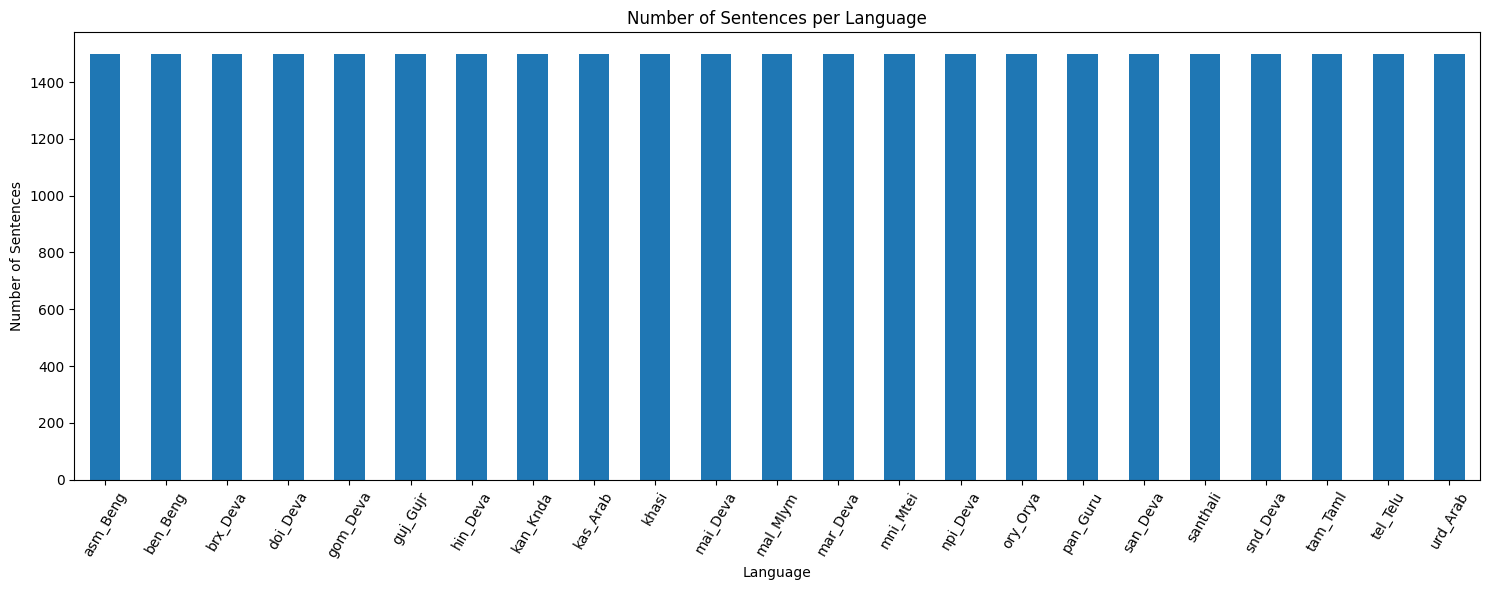

In [10]:
# ============================================================
# CELL 9 — CLASS DISTRIBUTION
# ============================================================

plt.figure(figsize=(15, 6))

counts.plot(kind="bar")

plt.title("Number of Sentences per Language")
plt.xlabel("Language")
plt.ylabel("Number of Sentences")

plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# CELL 10 — SAVE DATASET
# ============================================================

df.to_csv(
    "/content/indiccorp_language_dataset_1500.csv",
    index=False
)

print("Dataset saved successfully.")

print(
    "File: /content/indiccorp_language_dataset_1500.csv"
)

Dataset saved successfully.
File: /content/indiccorp_language_dataset_1500.csv


In [12]:
# ============================================================
# CELL 11 — STRATIFIED 80:10:10 SPLIT
# ============================================================

random.seed(42)

train_parts = []
val_parts = []
test_parts = []


for label in sorted(
    languages.keys()
):

    # Get one language
    subset = df[
        df["label"] == label
    ].sample(
        frac=1,
        random_state=42
    ).reset_index(
        drop=True
    )


    # --------------------------------------------------------
    # 1500 samples:
    #
    # 1200 train
    # 150 validation
    # 150 test
    # --------------------------------------------------------

    train_parts.append(
        subset.iloc[:1200]
    )

    val_parts.append(
        subset.iloc[1200:1350]
    )

    test_parts.append(
        subset.iloc[1350:1500]
    )


# Combine

train_df = pd.concat(
    train_parts,
    ignore_index=True
)

val_df = pd.concat(
    val_parts,
    ignore_index=True
)

test_df = pd.concat(
    test_parts,
    ignore_index=True
)


# Shuffle final sets

train_df = train_df.sample(
    frac=1,
    random_state=42
).reset_index(
    drop=True
)

val_df = val_df.sample(
    frac=1,
    random_state=42
).reset_index(
    drop=True
)

test_df = test_df.sample(
    frac=1,
    random_state=42
).reset_index(
    drop=True
)


# Results

print(
    "Training samples  :",
    len(train_df)
)

print(
    "Validation samples:",
    len(val_df)
)

print(
    "Test samples      :",
    len(test_df)
)

Training samples  : 27600
Validation samples: 3450
Test samples      : 3450


In [13]:
# ============================================================
# CELL 12 — VERIFY STRATIFIED SPLIT
# ============================================================

print("TRAINING DISTRIBUTION")
print(train_df["label"].value_counts().sort_index())

print("\nVALIDATION DISTRIBUTION")
print(val_df["label"].value_counts().sort_index())

print("\nTEST DISTRIBUTION")
print(test_df["label"].value_counts().sort_index())

TRAINING DISTRIBUTION
label
asm_Beng    1200
ben_Beng    1200
brx_Deva    1200
doi_Deva    1200
gom_Deva    1200
guj_Gujr    1200
hin_Deva    1200
kan_Knda    1200
kas_Arab    1200
khasi       1200
mai_Deva    1200
mal_Mlym    1200
mar_Deva    1200
mni_Mtei    1200
npi_Deva    1200
ory_Orya    1200
pan_Guru    1200
san_Deva    1200
santhali    1200
snd_Deva    1200
tam_Taml    1200
tel_Telu    1200
urd_Arab    1200
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
asm_Beng    150
ben_Beng    150
brx_Deva    150
doi_Deva    150
gom_Deva    150
guj_Gujr    150
hin_Deva    150
kan_Knda    150
kas_Arab    150
khasi       150
mai_Deva    150
mal_Mlym    150
mar_Deva    150
mni_Mtei    150
npi_Deva    150
ory_Orya    150
pan_Guru    150
san_Deva    150
santhali    150
snd_Deva    150
tam_Taml    150
tel_Telu    150
urd_Arab    150
Name: count, dtype: int64

TEST DISTRIBUTION
label
asm_Beng    150
ben_Beng    150
brx_Deva    150
doi_Deva    150
gom_Deva    150
guj_Gujr    150
hin_Deva 

In [14]:
# ============================================================
# CELL 13 — NUMERICAL LABELS (Label Encoding)
# ============================================================

label_names = sorted(
    languages.keys()
)

label_to_id = {
    label: i
    for i, label
    in enumerate(label_names)
}

id_to_label = {
    i: label
    for label, i
    in label_to_id.items()
}


train_df["label_id"] = (
    train_df["label"]
    .map(label_to_id)
)

val_df["label_id"] = (
    val_df["label"]
    .map(label_to_id)
)

test_df["label_id"] = (
    test_df["label"]
    .map(label_to_id)
)


num_classes = len(
    label_names
)


print(
    "Number of classes:",
    num_classes
)

print("\nLabel mapping:")

for i, label in id_to_label.items():

    print(
        i,
        "->",
        label,
        "(",
        languages[label],
        ")"
    )

Number of classes: 23

Label mapping:
0 -> asm_Beng ( Assamese )
1 -> ben_Beng ( Bengali )
2 -> brx_Deva ( Bodo )
3 -> doi_Deva ( Dogri )
4 -> gom_Deva ( Konkani )
5 -> guj_Gujr ( Gujarati )
6 -> hin_Deva ( Hindi )
7 -> kan_Knda ( Kannada )
8 -> kas_Arab ( Kashmiri )
9 -> khasi ( Khasi )
10 -> mai_Deva ( Maithili )
11 -> mal_Mlym ( Malayalam )
12 -> mar_Deva ( Marathi )
13 -> mni_Mtei ( Manipuri )
14 -> npi_Deva ( Nepali )
15 -> ory_Orya ( Odia )
16 -> pan_Guru ( Punjabi )
17 -> san_Deva ( Sanskrit )
18 -> santhali ( Santali )
19 -> snd_Deva ( Sindhi )
20 -> tam_Taml ( Tamil )
21 -> tel_Telu ( Telugu )
22 -> urd_Arab ( Urdu )


In [15]:
# ============================================================
# CHECK TRAINING LABELS
# ============================================================

y_train_check = (
    train_df["label_id"].values
)

print(
    "Total training samples:",
    len(y_train_check)
)

print(
    "Unique training classes:",
    len(np.unique(y_train_check))
)

print(
    "Classes present:",
    np.unique(y_train_check)
)

print(
    "\nSamples per class:"
)

print(
    pd.Series(y_train_check)
    .value_counts()
    .sort_index()
)

Total training samples: 27600
Unique training classes: 23
Classes present: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]

Samples per class:
0     1200
1     1200
2     1200
3     1200
4     1200
5     1200
6     1200
7     1200
8     1200
9     1200
10    1200
11    1200
12    1200
13    1200
14    1200
15    1200
16    1200
17    1200
18    1200
19    1200
20    1200
21    1200
22    1200
Name: count, dtype: int64


In [16]:
# ============================================================
# CELL 14 — CUSTOM TOKENIZATION
# ============================================================

def word_tokenize(text):

    # Unicode-aware word extraction
    tokens = re.findall(
        r'\w+',
        text,
        flags=re.UNICODE
    )

    return [
        token.lower()
        for token in tokens
    ]


def generate_word_ngrams(tokens):

    features = []

    # --------------------------------------------------------
    # Word Unigrams
    # --------------------------------------------------------

    for token in tokens:
        features.append(
            "WORD1_" + token
        )

    # --------------------------------------------------------
    # Word Bigrams
    # --------------------------------------------------------

    for i in range(
        len(tokens) - 1
    ):

        bigram = (
            tokens[i]
            + "_"
            + tokens[i + 1]
        )

        features.append(
            "WORD2_" + bigram
        )

    return features


def generate_char_ngrams(text):

    features = []

    text = text.lower()

    # Normalize spaces
    text = re.sub(
        r'\s+',
        ' ',
        text
    )

    # --------------------------------------------------------
    # Character 2, 3 and 4 grams
    # --------------------------------------------------------

    for n in [2, 3, 4]:

        for i in range(
            len(text) - n + 1
        ):

            gram = text[i:i+n]

            features.append(
                f"CHAR{n}_" + gram
            )

    return features


def extract_features(text):

    tokens = word_tokenize(text)

    word_features = generate_word_ngrams(
        tokens
    )

    char_features = generate_char_ngrams(
        text
    )

    return (
        word_features
        + char_features
    )


# Test

sample = train_df.iloc[0]["text"]

features = extract_features(sample)

print("Sample sentence:")
print(sample)

print("\nNumber of generated features:")
print(len(features))

print("\nFirst 30 features:")
print(features[:30])

Sample sentence:
بھروسہ کرنا، اعتماد کرنا، یقین کرنا

Number of generated features:
110

First 30 features:
['WORD1_بھروسہ', 'WORD1_کرنا', 'WORD1_اعتماد', 'WORD1_کرنا', 'WORD1_یقین', 'WORD1_کرنا', 'WORD2_بھروسہ_کرنا', 'WORD2_کرنا_اعتماد', 'WORD2_اعتماد_کرنا', 'WORD2_کرنا_یقین', 'WORD2_یقین_کرنا', 'CHAR2_بھ', 'CHAR2_ھر', 'CHAR2_رو', 'CHAR2_وس', 'CHAR2_سہ', 'CHAR2_ہ ', 'CHAR2_ ک', 'CHAR2_کر', 'CHAR2_رن', 'CHAR2_نا', 'CHAR2_ا،', 'CHAR2_، ', 'CHAR2_ ا', 'CHAR2_اع', 'CHAR2_عت', 'CHAR2_تم', 'CHAR2_ما', 'CHAR2_اد', 'CHAR2_د ']


In [17]:
# ============================================================
# CELL 15 — CUSTOM TF-IDF VECTORIZER
# ============================================================

class CustomTfidfVectorizer:

    def __init__(
        self,
        min_df=2,
        max_features=60000
    ):

        self.min_df = min_df
        self.max_features = max_features

        self.vocabulary = {}
        self.idf = None


    # --------------------------------------------------------
    # BUILD VOCABULARY
    # --------------------------------------------------------

    def build_vocabulary(
        self,
        documents
    ):

        document_frequency = Counter()

        print("Building vocabulary...")

        for i, document in enumerate(
            documents
        ):

            features = set(
                extract_features(
                    document
                )
            )

            document_frequency.update(
                features
            )

            if (
                (i + 1) % 2000 == 0
            ):

                print(
                    f"Processed {i+1} documents"
                )


        # Keep features occurring in at least
        # min_df documents

        valid_features = [
            (feature, frequency)
            for feature, frequency
            in document_frequency.items()
            if frequency >= self.min_df
        ]


        # Most frequent first

        valid_features.sort(
            key=lambda x: x[1],
            reverse=True
        )


        # Limit vocabulary

        valid_features = (
            valid_features[
                :self.max_features
            ]
        )


        # Create vocabulary

        self.vocabulary = {
            feature: index
            for index, (feature, _)
            in enumerate(valid_features)
        }


        print(
            "Vocabulary size:",
            len(self.vocabulary)
        )


        # ----------------------------------------------------
        # Calculate IDF
        # ----------------------------------------------------

        N = len(documents)

        self.idf = np.zeros(
            len(self.vocabulary),
            dtype=np.float32
        )

        for feature, index in (
            self.vocabulary.items()
        ):

            df = document_frequency[
                feature
            ]

            self.idf[index] = (
                np.log(
                    (N + 1) /
                    (df + 1)
                )
                + 1
            )


    # --------------------------------------------------------
    # TRANSFORM
    # --------------------------------------------------------

    def transform(
        self,
        documents
    ):

        rows = []
        cols = []
        values = []

        for row, document in enumerate(
            documents
        ):

            features = extract_features(
                document
            )

            counts = Counter(
                features
            )

            total_terms = sum(
                counts.values()
            )

            if total_terms == 0:
                continue


            for feature, count in (
                counts.items()
            ):

                if (
                    feature
                    not in self.vocabulary
                ):
                    continue

                col = self.vocabulary[
                    feature
                ]

                # Term Frequency

                tf = (
                    count /
                    total_terms
                )

                # TF-IDF

                tfidf = (
                    tf *
                    self.idf[col]
                )

                rows.append(row)
                cols.append(col)
                values.append(tfidf)


        X = csr_matrix(
            (
                np.array(
                    values,
                    dtype=np.float32
                ),
                (rows, cols)
            ),
            shape=(
                len(documents),
                len(self.vocabulary)
            ),
            dtype=np.float32
        )

        return X


    # --------------------------------------------------------
    # FIT + TRANSFORM
    # --------------------------------------------------------

    def fit_transform(
        self,
        documents
    ):

        self.build_vocabulary(
            documents
        )

        return self.transform(
            documents
        )

In [18]:
# ============================================================
# CELL 16 — FIT CUSTOM TF-IDF ON TRAINING DATA
# ============================================================

vectorizer = CustomTfidfVectorizer(
    min_df=2,
    max_features=60000
)

X_train = (
    vectorizer.fit_transform(
        train_df["text"].tolist()
    )
)

print(
    "\nTraining TF-IDF shape:"
)

print(
    X_train.shape
)

Building vocabulary...
Processed 2000 documents
Processed 4000 documents
Processed 6000 documents
Processed 8000 documents
Processed 10000 documents
Processed 12000 documents
Processed 14000 documents
Processed 16000 documents
Processed 18000 documents
Processed 20000 documents
Processed 22000 documents
Processed 24000 documents
Processed 26000 documents
Vocabulary size: 60000

Training TF-IDF shape:
(27600, 60000)


In [19]:
# ============================================================
# CELL 17 — TRANSFORM VALIDATION AND TEST DATA
# ============================================================

print("Transforming validation data...")

X_val = vectorizer.transform(
    val_df["text"].tolist()
)

print("Transforming test data...")

X_test = vectorizer.transform(
    test_df["text"].tolist()
)


print("\nTF-IDF MATRICES")
print("-" * 50)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

Transforming validation data...
Transforming test data...

TF-IDF MATRICES
--------------------------------------------------
X_train: (27600, 60000)
X_val  : (3450, 60000)
X_test : (3450, 60000)


In [20]:
# ============================================================
# CELL 16 — FIT CUSTOM TF-IDF
# ============================================================

vectorizer = CustomTfidfVectorizer(
    min_df=2,
    max_features=60000
)

X_train = (
    vectorizer.fit_transform(
        train_df["text"].tolist()
    )
)

print(
    "\nTraining TF-IDF shape:"
)

print(
    X_train.shape
)

Building vocabulary...
Processed 2000 documents
Processed 4000 documents
Processed 6000 documents
Processed 8000 documents
Processed 10000 documents
Processed 12000 documents
Processed 14000 documents
Processed 16000 documents
Processed 18000 documents
Processed 20000 documents
Processed 22000 documents
Processed 24000 documents
Processed 26000 documents
Vocabulary size: 60000

Training TF-IDF shape:
(27600, 60000)


In [21]:
# ============================================================
# CELL 17 — TRANSFORM VALIDATION AND TEST
# ============================================================

print(
    "Transforming validation data..."
)

X_val = (
    vectorizer.transform(
        val_df["text"].tolist()
    )
)


print(
    "Transforming test data..."
)

X_test = (
    vectorizer.transform(
        test_df["text"].tolist()
    )
)


print("\nTF-IDF MATRICES")
print("-" * 50)

print(
    "X_train:",
    X_train.shape
)

print(
    "X_val  :",
    X_val.shape
)

print(
    "X_test :",
    X_test.shape
)

Transforming validation data...
Transforming test data...

TF-IDF MATRICES
--------------------------------------------------
X_train: (27600, 60000)
X_val  : (3450, 60000)
X_test : (3450, 60000)


In [22]:
# ============================================================
# CELL 18 — PREPARE LABELS
# ============================================================

y_train = (
    train_df["label_id"].values
)

y_val = (
    val_df["label_id"].values
)

y_test = (
    test_df["label_id"].values
)


print(
    "y_train:",
    y_train.shape
)

print(
    "y_val  :",
    y_val.shape
)

print(
    "y_test :",
    y_test.shape
)


# Final safety check

assert len(
    np.unique(y_train)
) == 23, "Training data does not contain all 23 classes!"

assert len(
    np.unique(y_val)
) == 23, "Validation data does not contain all 23 classes!"

assert len(
    np.unique(y_test)
) == 23, "Test data does not contain all 23 classes!"

print(
    "\n✓ All 23 classes are present."
)

y_train: (27600,)
y_val  : (3450,)
y_test : (3450,)

✓ All 23 classes are present.


In [23]:
# ============================================================
# CELL 19 — CUSTOM MULTINOMIAL LOGISTIC REGRESSION
# ============================================================

class CustomLogisticRegression:

    def __init__(
        self,
        num_classes,
        learning_rate=0.5,
        epochs=15,
        batch_size=256,
        l2=1e-4,
        random_state=42
    ):

        self.num_classes = num_classes

        self.learning_rate = (
            learning_rate
        )

        self.epochs = epochs

        self.batch_size = (
            batch_size
        )

        self.l2 = l2

        self.random_state = (
            random_state
        )

        self.W = None
        self.b = None


    # --------------------------------------------------------
    # SOFTMAX
    # --------------------------------------------------------

    def softmax(self, Z):

        Z = Z - np.max(
            Z,
            axis=1,
            keepdims=True
        )

        exp_Z = np.exp(Z)

        return (
            exp_Z /
            np.sum(
                exp_Z,
                axis=1,
                keepdims=True
            )
        )


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    def fit(
        self,
        X,
        y,
        X_val=None,
        y_val=None
    ):

        np.random.seed(
            self.random_state
        )

        n_samples = X.shape[0]
        n_features = X.shape[1]

        # IMPORTANT:
        # Explicitly use 23 classes

        n_classes = (
            self.num_classes
        )


        # Initialize weights

        self.W = np.zeros(
            (
                n_features,
                n_classes
            ),
            dtype=np.float32
        )

        self.b = np.zeros(
            n_classes,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Epochs
        # ----------------------------------------------------

        for epoch in range(
            self.epochs
        ):

            indices = (
                np.random.permutation(
                    n_samples
                )
            )

            X_shuffled = X[
                indices
            ]

            y_shuffled = y[
                indices
            ]

            total_loss = 0.0


            # ------------------------------------------------
            # Mini-batches
            # ------------------------------------------------

            for start in range(
                0,
                n_samples,
                self.batch_size
            ):

                end = min(
                    start +
                    self.batch_size,
                    n_samples
                )

                X_batch = (
                    X_shuffled[
                        start:end
                    ]
                )

                y_batch = (
                    y_shuffled[
                        start:end
                    ]
                )

                batch_n = len(
                    y_batch
                )


                # Forward pass

                scores = (
                    X_batch @ self.W
                ) + self.b

                probabilities = (
                    self.softmax(
                        scores
                    )
                )


                # Cross entropy

                correct_probabilities = (
                    probabilities[
                        np.arange(batch_n),
                        y_batch
                    ]
                )

                loss = -np.mean(
                    np.log(
                        correct_probabilities
                        + 1e-12
                    )
                )


                # L2 regularization

                loss += (
                    self.l2 / 2
                ) * np.sum(
                    self.W *
                    self.W
                )

                total_loss += (
                    loss *
                    batch_n
                )


                # Gradient

                dZ = (
                    probabilities.copy()
                )

                dZ[
                    np.arange(batch_n),
                    y_batch
                ] -= 1

                dZ /= batch_n


                dW = (
                    X_batch.T @ dZ
                )

                dW += (
                    self.l2 *
                    self.W
                )


                db = np.sum(
                    dZ,
                    axis=0
                )


                # Update

                self.W -= (
                    self.learning_rate *
                    dW
                )

                self.b -= (
                    self.learning_rate *
                    db
                )


            # ------------------------------------------------
            # Epoch results
            # ------------------------------------------------

            average_loss = (
                total_loss /
                n_samples
            )


            train_predictions = (
                self.predict(X)
            )

            train_accuracy = np.mean(
                train_predictions == y
            )


            message = (
                f"Epoch {epoch + 1}/"
                f"{self.epochs} "
                f"| Loss: "
                f"{average_loss:.4f} "
                f"| Train Accuracy: "
                f"{train_accuracy:.4f}"
            )


            # Validation

            if (
                X_val is not None
                and y_val is not None
            ):

                val_predictions = (
                    self.predict(
                        X_val
                    )
                )

                val_accuracy = np.mean(
                    val_predictions ==
                    y_val
                )

                message += (
                    f" | Validation Accuracy: "
                    f"{val_accuracy:.4f}"
                )


            print(message)


    # --------------------------------------------------------
    # PREDICT PROBABILITIES
    # --------------------------------------------------------

    def predict_proba(self, X):

        scores = (
            X @ self.W
        ) + self.b

        return self.softmax(
            scores
        )


    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    def predict(self, X):

        probabilities = (
            self.predict_proba(X)
        )

        return np.argmax(
            probabilities,
            axis=1
        )

In [24]:
# ============================================================
# CELL 20 — TRAIN LOGISTIC REGRESSION
# ============================================================

model = CustomLogisticRegression(
    num_classes=num_classes,
    learning_rate=0.5,
    epochs=15,
    batch_size=256,
    l2=1e-4
)

model.fit(
    X_train,
    y_train,
    X_val,
    y_val
)

Epoch 1/15 | Loss: 3.1197 | Train Accuracy: 0.4935 | Validation Accuracy: 0.4791
Epoch 2/15 | Loss: 3.0864 | Train Accuracy: 0.7904 | Validation Accuracy: 0.7806
Epoch 3/15 | Loss: 3.0536 | Train Accuracy: 0.7793 | Validation Accuracy: 0.7710
Epoch 4/15 | Loss: 3.0215 | Train Accuracy: 0.8296 | Validation Accuracy: 0.8214
Epoch 5/15 | Loss: 2.9897 | Train Accuracy: 0.9124 | Validation Accuracy: 0.9061
Epoch 6/15 | Loss: 2.9586 | Train Accuracy: 0.8740 | Validation Accuracy: 0.8649
Epoch 7/15 | Loss: 2.9279 | Train Accuracy: 0.8775 | Validation Accuracy: 0.8713
Epoch 8/15 | Loss: 2.8978 | Train Accuracy: 0.9030 | Validation Accuracy: 0.8916
Epoch 9/15 | Loss: 2.8681 | Train Accuracy: 0.9207 | Validation Accuracy: 0.9110
Epoch 10/15 | Loss: 2.8391 | Train Accuracy: 0.9164 | Validation Accuracy: 0.9093
Epoch 11/15 | Loss: 2.8105 | Train Accuracy: 0.9414 | Validation Accuracy: 0.9307
Epoch 12/15 | Loss: 2.7824 | Train Accuracy: 0.9210 | Validation Accuracy: 0.9090
Epoch 13/15 | Loss: 2.755

In [25]:
# ============================================================
# CELL 21 — TEST PREDICTIONS AND ACCURACY
# ============================================================

y_pred = model.predict(
    X_test
)


def accuracy_manual(
    y_true,
    y_pred
):

    return np.mean(
        y_true == y_pred
    )


test_accuracy = accuracy_manual(
    y_test,
    y_pred
)

print(
    f"Test Accuracy: "
    f"{test_accuracy:.4f}"
)

Test Accuracy: 0.9232


In [26]:
# ============================================================
# CELL 22 — MANUAL MACRO-F1
# ============================================================

def calculate_macro_f1(
    y_true,
    y_pred,
    num_classes
):

    f1_scores = []

    for c in range(
        num_classes
    ):

        # True Positive
        tp = np.sum(
            (y_true == c) &
            (y_pred == c)
        )

        # False Positive
        fp = np.sum(
            (y_true != c) &
            (y_pred == c)
        )

        # False Negative
        fn = np.sum(
            (y_true == c) &
            (y_pred != c)
        )


        # Precision

        if (
            tp + fp
        ) > 0:

            precision = (
                tp /
                (tp + fp)
            )

        else:

            precision = 0.0


        # Recall

        if (
            tp + fn
        ) > 0:

            recall = (
                tp /
                (tp + fn)
            )

        else:

            recall = 0.0


        # F1

        if (
            precision + recall
        ) > 0:

            f1 = (
                2 *
                precision *
                recall
                /
                (precision + recall)
            )

        else:

            f1 = 0.0


        f1_scores.append(
            f1
        )


    # Macro average

    macro_f1 = np.mean(
        f1_scores
    )

    return (
        macro_f1,
        f1_scores
    )


macro_f1, class_f1 = (
    calculate_macro_f1(
        y_test,
        y_pred,
        num_classes
    )
)


print(
    f"Macro-F1 Score: "
    f"{macro_f1:.4f}"
)

Macro-F1 Score: 0.9079


In [27]:
# ============================================================
# CELL 23 — CLASS-WISE F1 SCORES
# ============================================================

results = pd.DataFrame({
    "Language Code": label_names,
    "Language": [
        languages[label]
        for label in label_names
    ],
    "F1 Score": class_f1
})

results = results.sort_values(
    "F1 Score",
    ascending=False
).reset_index(drop=True)

print(
    results.to_string(
        index=False
    )
)

Language Code  Language  F1 Score
     guj_Gujr  Gujarati  1.000000
     santhali   Santali  1.000000
     tam_Taml     Tamil  1.000000
     tel_Telu    Telugu  1.000000
     pan_Guru   Punjabi  1.000000
     mal_Mlym Malayalam  1.000000
     kan_Knda   Kannada  1.000000
     ory_Orya      Odia  1.000000
     snd_Deva    Sindhi  0.996656
     asm_Beng  Assamese  0.993377
     ben_Beng   Bengali  0.993333
     urd_Arab      Urdu  0.990099
     kas_Arab  Kashmiri  0.989899
     mni_Mtei  Manipuri  0.986486
     san_Deva  Sanskrit  0.967320
        khasi     Khasi  0.943396
     npi_Deva    Nepali  0.938511
     mai_Deva  Maithili  0.881944
     doi_Deva     Dogri  0.868687
     brx_Deva      Bodo  0.840278
     hin_Deva     Hindi  0.800000
     mar_Deva   Marathi  0.679335
     gom_Deva   Konkani  0.013245


In [28]:
# ============================================================
# CELL 24 — MANUAL CONFUSION MATRIX
# ============================================================

def confusion_matrix_manual(
    y_true,
    y_pred,
    num_classes
):

    cm = np.zeros(
        (
            num_classes,
            num_classes
        ),
        dtype=int
    )

    for true_label, predicted_label in zip(
        y_true,
        y_pred
    ):

        cm[
            true_label,
            predicted_label
        ] += 1

    return cm


cm = confusion_matrix_manual(
    y_test,
    y_pred,
    num_classes
)

print("Confusion matrix shape:")
print(cm.shape)

Confusion matrix shape:
(23, 23)


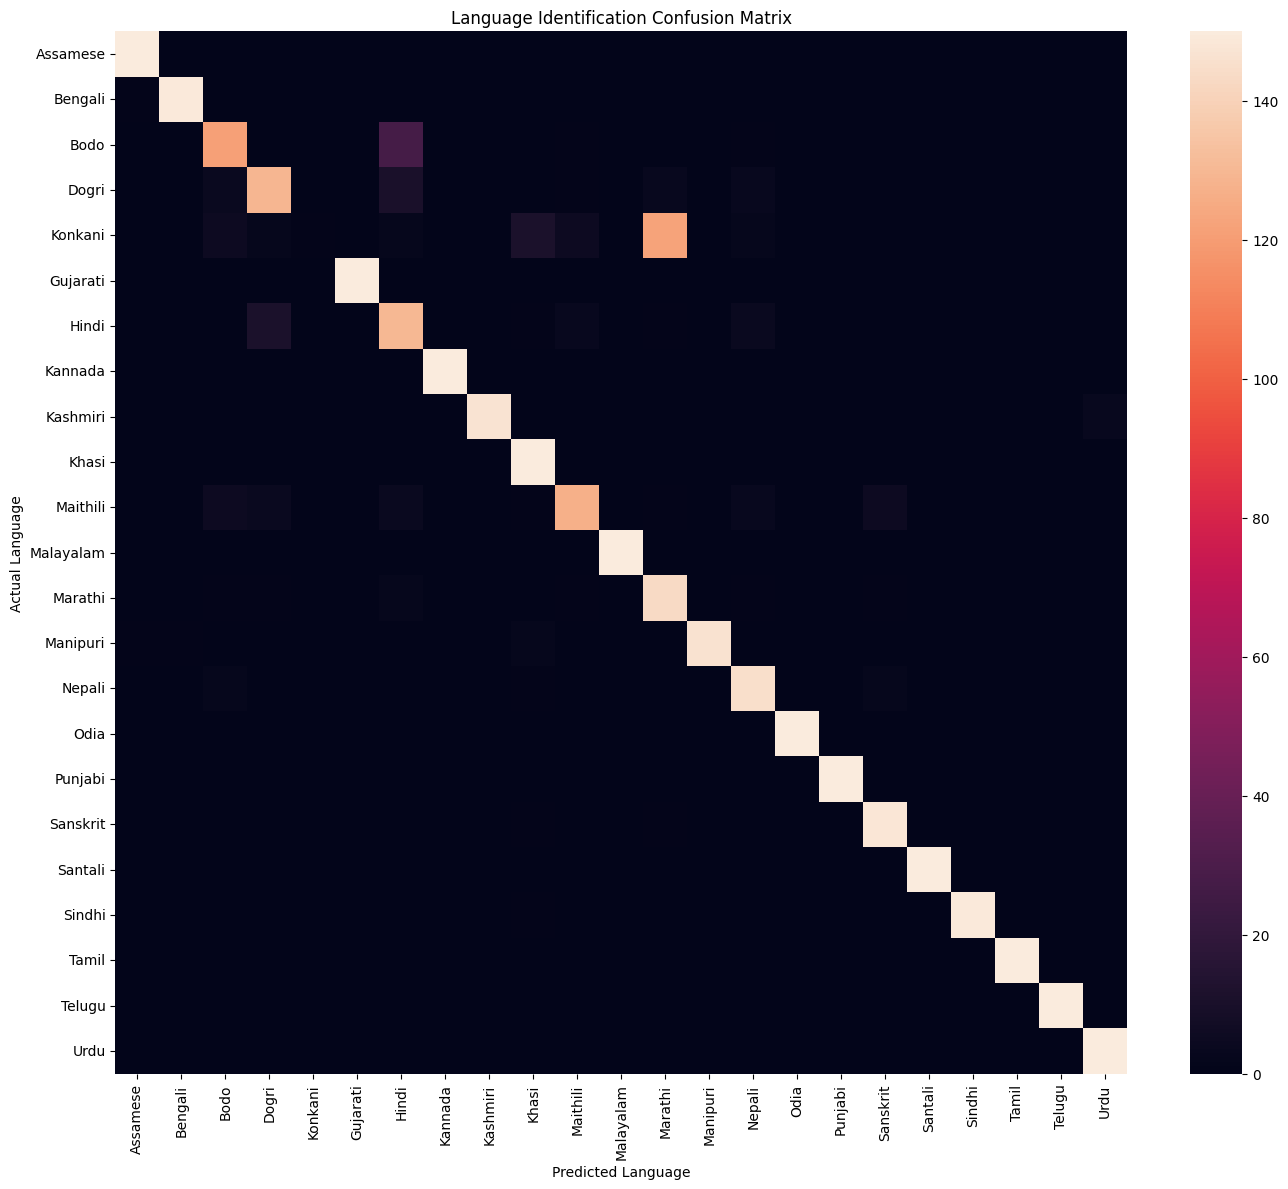

In [29]:
# ============================================================
# CELL 25 — CONFUSION MATRIX VISUALIZATION
# ============================================================

plt.figure(
    figsize=(14, 12)
)

sns.heatmap(
    cm,
    annot=False,
    fmt="d",
    xticklabels=[
        languages[label]
        for label in label_names
    ],
    yticklabels=[
        languages[label]
        for label in label_names
    ]
)

plt.xlabel(
    "Predicted Language"
)

plt.ylabel(
    "Actual Language"
)

plt.title(
    "Language Identification Confusion Matrix"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [30]:
# ============================================================
# CELL 26 — FINAL RESULTS
# ============================================================

print("=" * 60)
print("FINAL LANGUAGE IDENTIFICATION RESULTS")
print("=" * 60)

print(
    f"Number of languages       : {num_classes}"
)

print(
    f"Samples per language      : {SAMPLES_PER_LANGUAGE}"
)

print(
    f"Total dataset samples     : {len(df)}"
)

print(
    f"Training samples          : {len(train_df)}"
)

print(
    f"Validation samples        : {len(val_df)}"
)

print(
    f"Test samples              : {len(test_df)}"
)

print(
    f"TF-IDF vocabulary size    : {len(vectorizer.vocabulary)}"
)

print(
    f"Test Accuracy             : {test_accuracy:.4f}"
)

print(
    f"Macro-F1 Score            : {macro_f1:.4f}"
)


FINAL LANGUAGE IDENTIFICATION RESULTS
Number of languages       : 23
Samples per language      : 1500
Total dataset samples     : 34500
Training samples          : 27600
Validation samples        : 3450
Test samples              : 3450
TF-IDF vocabulary size    : 60000
Test Accuracy             : 0.9232
Macro-F1 Score            : 0.9079


In [31]:
# ============================================================
# CELL 27 — DEMO
# ============================================================

def identify_language(text):

    X = vectorizer.transform(
        [text]
    )

    prediction = (
        model.predict(X)[0]
    )

    probabilities = (
        model.predict_proba(X)[0]
    )

    confidence = (
        probabilities[
            prediction
        ]
    )

    language_code = (
        id_to_label[
            prediction
        ]
    )

    language_name = (
        languages[
            language_code
        ]
    )

    return (
        language_code,
        language_name,
        confidence
    )


# Hindi

text1 = (
    "भारत एक विविधताओं से भरा हुआ देश है।"
)

code, name, confidence = (
    identify_language(text1)
)

print("Input:", text1)
print("Predicted:", name)
print("Code:", code)
print(
    "Confidence:",
    round(
        float(confidence),
        4
    )
)


# Tamil

text2 = (
    "தமிழ் மொழி மிகவும் பழமையான "
    "மொழிகளில் ஒன்றாகும்."
)

code, name, confidence = (
    identify_language(text2)
)

print("\nInput:", text2)
print("Predicted:", name)
print("Code:", code)
print(
    "Confidence:",
    round(
        float(confidence),
        4
    )
)


# Telugu

text3 = (
    "తెలుగు భారతదేశంలో మాట్లాడే "
    "ప్రధాన భాషలలో ఒకటి."
)

code, name, confidence = (
    identify_language(text3)
)

print("\nInput:", text3)
print("Predicted:", name)
print("Code:", code)
print(
    "Confidence:",
    round(
        float(confidence),
        4
    )
)

Input: भारत एक विविधताओं से भरा हुआ देश है।
Predicted: Hindi
Code: hin_Deva
Confidence: 0.0524

Input: தமிழ் மொழி மிகவும் பழமையான மொழிகளில் ஒன்றாகும்.
Predicted: Tamil
Code: tam_Taml
Confidence: 0.091

Input: తెలుగు భారతదేశంలో మాట్లాడే ప్రధాన భాషలలో ఒకటి.
Predicted: Telugu
Code: tel_Telu
Confidence: 0.0749


#Assignment 2

In [33]:
# ============================================================
# CELL 28 — TF AND IDF NORMALIZATION FUNCTIONS
# ============================================================

import numpy as np
from collections import Counter
from scipy.sparse import csr_matrix

print("Preparing TF and IDF normalization functions...")

Preparing TF and IDF normalization functions...


In [34]:
# ============================================================
# CELL 29 — COMPUTE DOCUMENT FREQUENCY AND IDF
# ============================================================

def compute_document_frequencies(documents, vocabulary):

    df_counts = np.zeros(
        len(vocabulary),
        dtype=np.int32
    )

    for i, document in enumerate(documents):

        features = extract_features(
            document
        )

        unique_features = set(features)

        for feature in unique_features:

            if feature in vocabulary:

                index = vocabulary[feature]

                df_counts[index] += 1

        if (i + 1) % 2000 == 0:

            print(
                f"Processed {i + 1} documents"
            )

    return df_counts


print("Computing document frequencies...")

document_frequencies = compute_document_frequencies(
    train_df["text"].tolist(),
    vectorizer.vocabulary
)

N = len(train_df)

print("\nNumber of training documents:", N)
print(
    "Number of vocabulary terms:",
    len(vectorizer.vocabulary)
)

Computing document frequencies...
Processed 2000 documents
Processed 4000 documents
Processed 6000 documents
Processed 8000 documents
Processed 10000 documents
Processed 12000 documents
Processed 14000 documents
Processed 16000 documents
Processed 18000 documents
Processed 20000 documents
Processed 22000 documents
Processed 24000 documents
Processed 26000 documents

Number of training documents: 27600
Number of vocabulary terms: 60000


In [35]:
# ============================================================
# CELL 30 — UNNORMALIZED AND NORMALIZED IDF
# ============================================================

# ------------------------------------------------------------
# Unnormalized IDF
# ------------------------------------------------------------

idf_unnormalized = np.log(
    (N + 1) /
    (document_frequencies + 1)
) + 1


# ------------------------------------------------------------
# Normalized IDF
# ------------------------------------------------------------

max_idf = np.max(
    idf_unnormalized
)

idf_normalized = (
    idf_unnormalized /
    max_idf
)


print(
    "Maximum unnormalized IDF:",
    max_idf
)

print(
    "Maximum normalized IDF:",
    np.max(idf_normalized)
)

print(
    "Minimum normalized IDF:",
    np.min(idf_normalized)
)

Maximum unnormalized IDF: 8.134564829574625
Maximum normalized IDF: 1.0
Minimum normalized IDF: 0.29746919727430216


In [36]:
# ============================================================
# CELL 31 — THREE TYPES OF TF
# ============================================================

def calculate_tf(
    features,
    vocabulary,
    tf_type
):

    counts = Counter(
        features
    )

    values = {}

    # --------------------------------------------------------
    # Maximum frequency in this document
    # --------------------------------------------------------

    max_frequency = max(
        counts.values()
    ) if counts else 1


    # --------------------------------------------------------
    # Total number of words/features
    # --------------------------------------------------------

    total_frequency = sum(
        counts.values()
    )

    if total_frequency == 0:
        total_frequency = 1


    # --------------------------------------------------------
    # Calculate TF
    # --------------------------------------------------------

    for feature, count in counts.items():

        if feature not in vocabulary:
            continue

        index = vocabulary[
            feature
        ]


        # 1. UNNORMALIZED TF

        if tf_type == "unnormalized":

            tf = count


        # 2. NORMALIZED BY TOTAL NUMBER OF WORDS

        elif tf_type == "total_words":

            tf = (
                count /
                total_frequency
            )


        # 3. NORMALIZED BY MOST FREQUENT WORD

        elif tf_type == "max_frequency":

            tf = (
                count /
                max_frequency
            )


        else:

            raise ValueError(
                "Unknown TF type"
            )


        values[index] = tf


    return values

In [37]:
# ============================================================
# CELL 32 — BUILD TF-IDF MATRIX
# ============================================================

def build_tfidf_matrix(
    documents,
    vocabulary,
    idf_values,
    tf_type
):

    rows = []
    cols = []
    values = []


    for row, document in enumerate(
        documents
    ):

        features = extract_features(
            document
        )


        tf_values = calculate_tf(
            features,
            vocabulary,
            tf_type
        )


        for col, tf in tf_values.items():

            tfidf = (
                tf *
                idf_values[col]
            )


            rows.append(row)
            cols.append(col)
            values.append(tfidf)


        if (
            (row + 1) % 2000 == 0
        ):

            print(
                f"Processed "
                f"{row + 1} documents"
            )


    matrix = csr_matrix(
        (
            np.array(
                values,
                dtype=np.float32
            ),
            (
                rows,
                cols
            )
        ),
        shape=(
            len(documents),
            len(vocabulary)
        ),
        dtype=np.float32
    )


    return matrix

In [38]:
# ============================================================
# CELL 33 — CREATE ALL 6 TF-IDF COMBINATIONS
# ============================================================

tf_types = [
    "unnormalized",
    "total_words",
    "max_frequency"
]

tf_names = {
    "unnormalized":
        "Unnormalized TF",

    "total_words":
        "Total-Words Normalized TF",

    "max_frequency":
        "Maximum-Frequency Normalized TF"
}


idf_types = {
    "unnormalized":
        (
            "Unnormalized IDF",
            idf_unnormalized
        ),

    "normalized":
        (
            "Normalized IDF",
            idf_normalized
        )
}


tfidf_matrices = {}


for tf_type in tf_types:

    for idf_type in [
        "unnormalized",
        "normalized"
    ]:

        combination_name = (
            tf_type +
            "_" +
            idf_type
        )


        print("\n" + "=" * 70)

        print(
            "Creating:",
            tf_names[tf_type],
            "+",
            idf_types[idf_type][0]
        )

        print("=" * 70)


        idf_values = (
            idf_types[idf_type][1]
        )


        # TRAIN

        X_train_combination = (
            build_tfidf_matrix(
                train_df["text"].tolist(),
                vectorizer.vocabulary,
                idf_values,
                tf_type
            )
        )


        # VALIDATION

        X_val_combination = (
            build_tfidf_matrix(
                val_df["text"].tolist(),
                vectorizer.vocabulary,
                idf_values,
                tf_type
            )
        )


        # TEST

        X_test_combination = (
            build_tfidf_matrix(
                test_df["text"].tolist(),
                vectorizer.vocabulary,
                idf_values,
                tf_type
            )
        )


        tfidf_matrices[
            combination_name
        ] = {
            "X_train":
                X_train_combination,

            "X_val":
                X_val_combination,

            "X_test":
                X_test_combination,

            "tf_name":
                tf_names[tf_type],

            "idf_name":
                idf_types[idf_type][0]
        }


        print(
            "Train shape:",
            X_train_combination.shape
        )

        print(
            "Validation shape:",
            X_val_combination.shape
        )

        print(
            "Test shape:",
            X_test_combination.shape
        )


Creating: Unnormalized TF + Unnormalized IDF
Processed 2000 documents
Processed 4000 documents
Processed 6000 documents
Processed 8000 documents
Processed 10000 documents
Processed 12000 documents
Processed 14000 documents
Processed 16000 documents
Processed 18000 documents
Processed 20000 documents
Processed 22000 documents
Processed 24000 documents
Processed 26000 documents
Processed 2000 documents
Processed 2000 documents
Train shape: (27600, 60000)
Validation shape: (3450, 60000)
Test shape: (3450, 60000)

Creating: Unnormalized TF + Normalized IDF
Processed 2000 documents
Processed 4000 documents
Processed 6000 documents
Processed 8000 documents
Processed 10000 documents
Processed 12000 documents
Processed 14000 documents
Processed 16000 documents
Processed 18000 documents
Processed 20000 documents
Processed 22000 documents
Processed 24000 documents
Processed 26000 documents
Processed 2000 documents
Processed 2000 documents
Train shape: (27600, 60000)
Validation shape: (3450, 600

In [39]:
# ============================================================
# CELL 34 — VERIFY SIX COMBINATIONS
# ============================================================

print(
    "Number of TF-IDF combinations:",
    len(tfidf_matrices)
)

print()

for name, data in tfidf_matrices.items():

    print(
        name,
        "->",
        data["X_train"].shape
    )

Number of TF-IDF combinations: 6

unnormalized_unnormalized -> (27600, 60000)
unnormalized_normalized -> (27600, 60000)
total_words_unnormalized -> (27600, 60000)
total_words_normalized -> (27600, 60000)
max_frequency_unnormalized -> (27600, 60000)
max_frequency_normalized -> (27600, 60000)


In [40]:
# ============================================================
# CELL 35 — TRAIN LOGISTIC REGRESSION FOR ALL 6 COMBINATIONS
# ============================================================

results = []


for combination_name, data in (
    tfidf_matrices.items()
):

    print("\n")
    print("#" * 80)

    print(
        "TRAINING:",
        combination_name
    )

    print("#" * 80)


    X_train_current = (
        data["X_train"]
    )

    X_val_current = (
        data["X_val"]
    )

    X_test_current = (
        data["X_test"]
    )


    # --------------------------------------------------------
    # Create fresh model
    # --------------------------------------------------------

    current_model = (
        CustomLogisticRegression(
            num_classes=num_classes,
            learning_rate=0.5,
            epochs=15,
            batch_size=256,
            l2=1e-4
        )
    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    current_model.fit(
        X_train_current,
        y_train,
        X_val_current,
        y_val
    )


    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    predictions = (
        current_model.predict(
            X_test_current
        )
    )


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    accuracy = np.mean(
        predictions == y_test
    )


    # --------------------------------------------------------
    # Macro-F1
    # --------------------------------------------------------

    macro_f1_score, _ = (
        calculate_macro_f1(
            y_test,
            predictions,
            num_classes
        )
    )


    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    results.append({

        "Combination":
            combination_name,

        "TF":
            data["tf_name"],

        "IDF":
            data["idf_name"],

        "Accuracy":
            accuracy,

        "Macro-F1":
            macro_f1_score
    })


    print(
        "\nTest Accuracy:",
        round(
            accuracy,
            4
        )
    )

    print(
        "Test Macro-F1:",
        round(
            macro_f1_score,
            4
        )
    )



################################################################################
TRAINING: unnormalized_unnormalized
################################################################################
Epoch 1/15 | Loss: 0.6405 | Train Accuracy: 0.9780 | Validation Accuracy: 0.9446
Epoch 2/15 | Loss: 0.1888 | Train Accuracy: 0.9836 | Validation Accuracy: 0.9449
Epoch 3/15 | Loss: 0.0906 | Train Accuracy: 0.9759 | Validation Accuracy: 0.9380
Epoch 4/15 | Loss: 0.0493 | Train Accuracy: 0.9974 | Validation Accuracy: 0.9507
Epoch 5/15 | Loss: 0.0216 | Train Accuracy: 0.9977 | Validation Accuracy: 0.9528
Epoch 6/15 | Loss: 0.0189 | Train Accuracy: 0.9987 | Validation Accuracy: 0.9507
Epoch 7/15 | Loss: 0.0162 | Train Accuracy: 0.9996 | Validation Accuracy: 0.9530
Epoch 8/15 | Loss: 0.0129 | Train Accuracy: 0.9998 | Validation Accuracy: 0.9528
Epoch 9/15 | Loss: 0.0113 | Train Accuracy: 1.0000 | Validation Accuracy: 0.9522
Epoch 10/15 | Loss: 0.0109 | Train Accuracy: 1.0000 | Validation Accura

In [41]:
# ============================================================
# CELL 36 — COMPARE ALL SIX MODELS
# ============================================================

results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(
    "Macro-F1",
    ascending=False
).reset_index(
    drop=True
)


print(
    results_df.to_string(
        index=False
    )
)

               Combination                              TF              IDF  Accuracy  Macro-F1
max_frequency_unnormalized Maximum-Frequency Normalized TF Unnormalized IDF  0.959130  0.959289
   unnormalized_normalized                 Unnormalized TF   Normalized IDF  0.958261  0.958401
 unnormalized_unnormalized                 Unnormalized TF Unnormalized IDF  0.954203  0.954464
  max_frequency_normalized Maximum-Frequency Normalized TF   Normalized IDF  0.947536  0.947585
  total_words_unnormalized       Total-Words Normalized TF Unnormalized IDF  0.923188  0.907938
    total_words_normalized       Total-Words Normalized TF   Normalized IDF  0.127536  0.098045


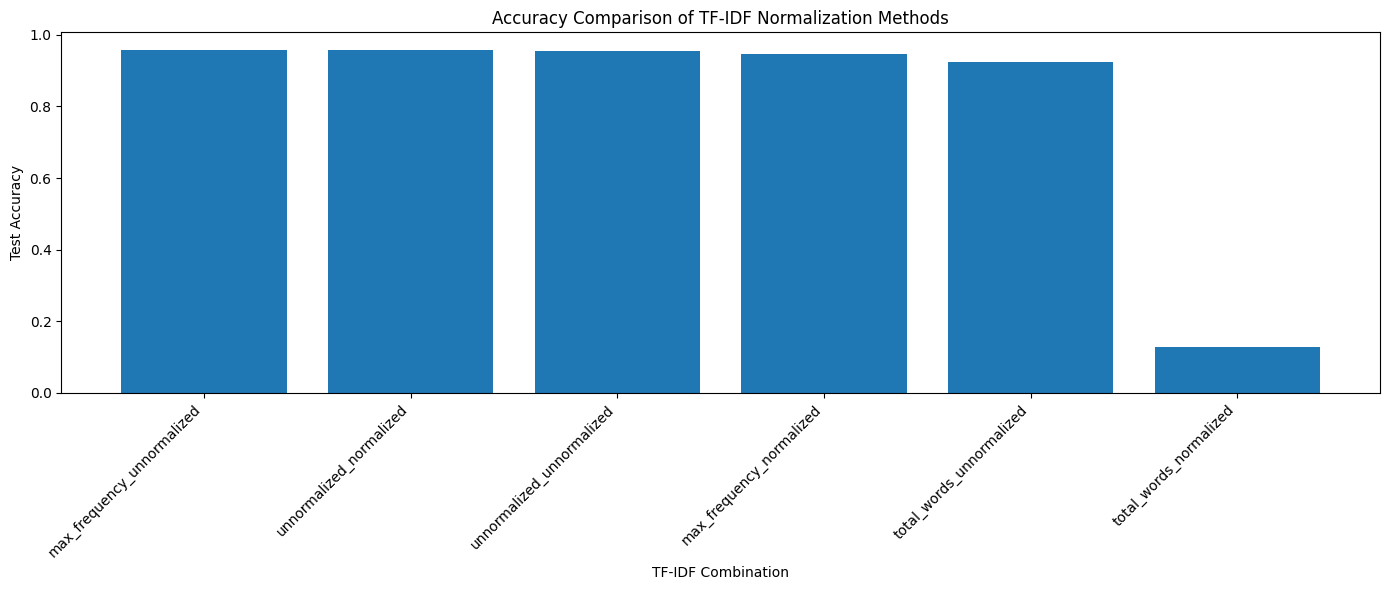

In [42]:
# ============================================================
# CELL 37 — ACCURACY COMPARISON
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.bar(
    results_df["Combination"],
    results_df["Accuracy"]
)

plt.title(
    "Accuracy Comparison of TF-IDF Normalization Methods"
)

plt.xlabel(
    "TF-IDF Combination"
)

plt.ylabel(
    "Test Accuracy"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

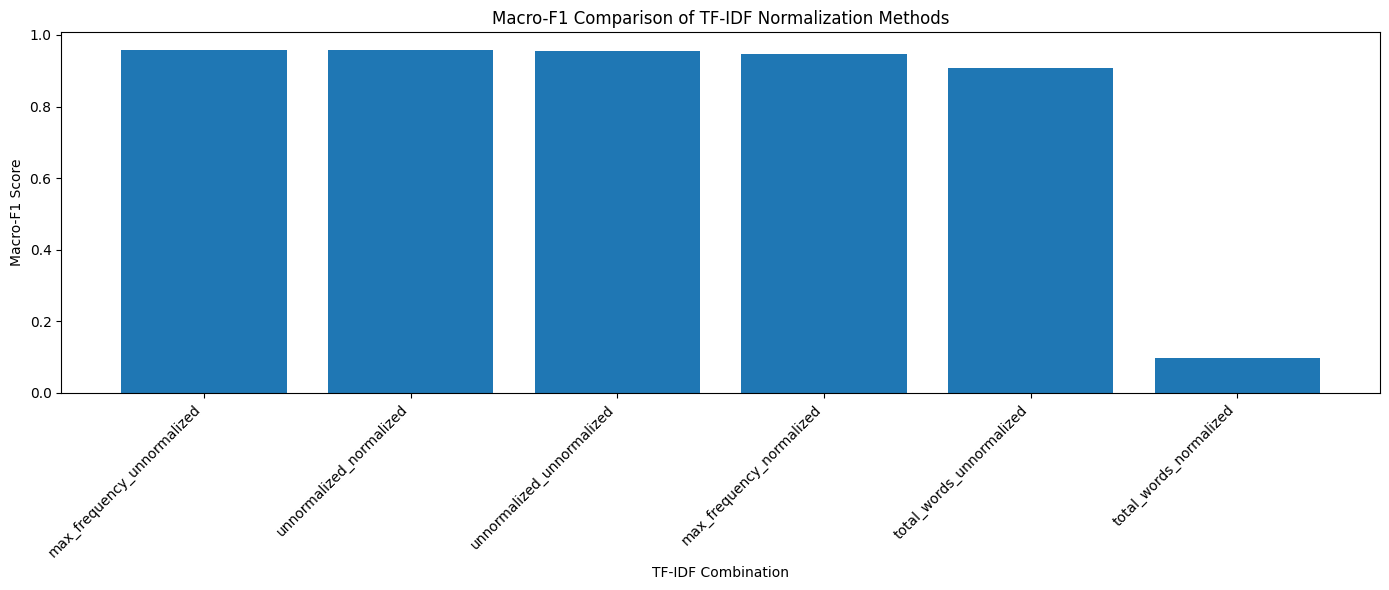

In [43]:
# ============================================================
# CELL 38 — MACRO-F1 COMPARISON
# ============================================================

plt.figure(
    figsize=(14, 6)
)

plt.bar(
    results_df["Combination"],
    results_df["Macro-F1"]
)

plt.title(
    "Macro-F1 Comparison of TF-IDF Normalization Methods"
)

plt.xlabel(
    "TF-IDF Combination"
)

plt.ylabel(
    "Macro-F1 Score"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

In [44]:
# ============================================================
# CELL 39 — BEST MODEL
# ============================================================

best_model = (
    results_df.iloc[0]
)


print("=" * 70)

print(
    "BEST TF-IDF COMBINATION"
)

print("=" * 70)


print(
    "TF:",
    best_model["TF"]
)

print(
    "IDF:",
    best_model["IDF"]
)

print(
    "Accuracy:",
    round(
        best_model["Accuracy"],
        4
    )
)

print(
    "Macro-F1:",
    round(
        best_model["Macro-F1"],
        4
    )
)

BEST TF-IDF COMBINATION
TF: Maximum-Frequency Normalized TF
IDF: Unnormalized IDF
Accuracy: 0.9591
Macro-F1: 0.9593


In [45]:
# ============================================================
# CELL 40 — COMPARE WITH ORIGINAL UNNORMALIZED MODEL
# ============================================================

# These two values should be taken from
# your previous assignment's final output.

original_accuracy = test_accuracy
original_macro_f1 = macro_f1


print("=" * 70)

print(
    "ORIGINAL MODEL VS NORMALIZATION EXPERIMENT"
)

print("=" * 70)


print(
    "\nOriginal Unnormalized TF-IDF:"
)

print(
    "Accuracy :",
    round(
        original_accuracy,
        4
    )
)

print(
    "Macro-F1 :",
    round(
        original_macro_f1,
        4
    )
)


print(
    "\nSix normalization combinations:"
)

print(
    results_df[
        [
            "Combination",
            "Accuracy",
            "Macro-F1"
        ]
    ].to_string(
        index=False
    )
)

ORIGINAL MODEL VS NORMALIZATION EXPERIMENT

Original Unnormalized TF-IDF:
Accuracy : 0.9232
Macro-F1 : 0.9079

Six normalization combinations:
               Combination  Accuracy  Macro-F1
max_frequency_unnormalized  0.959130  0.959289
   unnormalized_normalized  0.958261  0.958401
 unnormalized_unnormalized  0.954203  0.954464
  max_frequency_normalized  0.947536  0.947585
  total_words_unnormalized  0.923188  0.907938
    total_words_normalized  0.127536  0.098045
